## Statistical Analysis of Concrete Compressive Strength

### 1. Research Objective
#### 研究目的
本プロジェクトでは、Pythonを用いて、コンクリートの材料配合条件および養生期間と圧縮強度の関係を統計的に分析する。

### 2. Dataset Description
   #### 資料說明

In [1]:
import pandas as pd

df = pd.read_csv("concrete_data.csv")
df.head()

,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   cement                         1030 non-null   float64
 1   blast_furnace_slag             1030 non-null   float64
 2   fly_ash                        1030 non-null   float64
 3   water                          1030 non-null   float64
 4   superplasticizer               1030 non-null   float64
 5   coarse_aggregate               1030 non-null   float64
 6   fine_aggregate                 1030 non-null   float64
 7   age                            1030 non-null   int64  
 8   concrete_compressive_strength  1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


In [3]:
df.describe()

,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.167864,73.895825,54.188350,181.567282,6.204660,972.918932,773.580485,45.662136,35.817961
std,104.506364,86.279342,63.997004,21.354219,5.973841,77.753954,80.175980,63.169912,16.705742
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.710000
50%,272.900000,22.000000,0.000000,185.000000,6.400000,968.000000,779.500000,28.000000,34.445000
75%,350.000000,142.950000,118.300000,192.000000,10.200000,1029.400000,824.000000,56.000000,46.135000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


### 3. Data Quality Assessment
   #### 3.1 Zero Values

In [4]:
import numpy as np

print(f"Number of samples with zero fly ash content:",(df["fly_ash"]==0).sum())

Number of samples with zero fly ash content: 566


全1,030件のデータのうち、566件で飛灰（fly_ash）の使用量が0となっていた。この結果については注意が必要である。
fly_ash = 0 は、材料配合に飛灰が使用されていないことを示していると考えられ、欠損値を意味するものではない。<br>
したがって、これらのゼロ値を欠損値（NaN）として扱い、安易に削除することは適切ではない。

In [5]:
print(f"Number of Zero Values in Each Column:")
print((df == 0).sum(axis = 0))

Number of Zero Values in Each Column:
cement                             0
blast_furnace_slag               471
fly_ash                          566
water                              0
superplasticizer                 379
coarse_aggregate                   0
fine_aggregate                     0
age                                0
concrete_compressive_strength      0
dtype: int64


データを確認したところ、以下の3つの変数に多数のゼロ値が含まれていた。
blast_furnace_slag（高炉スラグ）：471件<br>
fly_ash（フライアッシュ）：566件<br>
superplasticizer（高性能減水剤）：379件<br>
これらの変数は、コンクリートの材料配合量を表している。
そのため、値が0であることは、該当する材料が配合されていないことを意味すると考えられ、必ずしも欠損値を示すものではない。<br>
これらのゼロ値を欠損値（NaN）として扱い、削除してしまうと、特定の材料を使用していない配合条件のデータが分析対象から除外され、解析結果に偏りが生じる可能性がある。
したがって、本分析では、これらのゼロ値を有効な測定データとして扱い、削除せずに保持することとした。

 #### 3.2 Duplicate Records

In [6]:
duplicates_all = df.loc[df.duplicated(keep=False)]
print("Number of rows in duplicate groups:", len(duplicates_all))
duplicates_all

Number of rows in duplicate groups: 36


,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
72,425.0,106.3,0.0,153.5,16.5,852.1,887.1,3,33.40
77,425.0,106.3,0.0,153.5,16.5,852.1,887.1,3,33.40
80,425.0,106.3,0.0,153.5,16.5,852.1,887.1,3,33.40
83,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.30
86,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.30
88,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.30
91,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.30
95,425.0,106.3,0.0,153.5,16.5,852.1,887.1,7,49.20
100,425.0,106.3,0.0,153.5,16.5,852.1,887.1,7,49.20
103,425.0,106.3,0.0,153.5,16.5,852.1,887.1,7,49.20


### 3.3 重複データの特徴と取り扱い

全1,030件のデータを確認したところ、完全に一致する重複行が25件検出された。

`duplicated(keep=False)` を用いて、重複元のデータも含めて抽出した結果、合計36件、11グループの重複データが確認された。

重複データの内容を詳しく確認したところ、主に以下の2種類の材料配合条件に集中していることが分かった。

#### ① 配合条件 A

| 材料                 | 配合量（kg/m³） |
| ------------------ | ---------: |
| cement             |      425.0 |
| blast_furnace_slag |      106.3 |
| fly_ash            |        0.0 |
| water              |      153.5 |
| superplasticizer   |       16.5 |
| coarse_aggregate   |      852.1 |
| fine_aggregate     |      887.1 |

この配合条件では、以下の養生期間において、圧縮強度の測定値が完全に一致するレコードが複数存在していた。

| 養生期間（日） | 圧縮強度（MPa） | 同一レコード数 |
| :------:| :--------: | :------: |
|       3 |     33.40 |       3 |
|       7 |     49.20 |       3 |
|      28 |     60.29 |       3 |
|      56 |     64.30 |       3 |
|      91 |     65.20 |       3 |

#### ② 配合条件 B

| 材料                 | 配合量（kg/m³） |
| ------------------ | ---------: |
| cement             |      362.6 |
| blast_furnace_slag |      189.0 |
| fly_ash            |        0.0 |
| water              |      164.9 |
| superplasticizer   |       11.6 |
| coarse_aggregate   |      944.7 |
| fine_aggregate     |      755.8 |

この配合条件についても、複数の養生期間において、同一の測定値を持つレコードが確認された。

| 養生期間（日） | 圧縮強度（MPa） | 同一レコード数 |
| :------: | :--------: | :------: |
|       3 |     35.30 |       4 |
|       7 |     55.90 |       3 |
|      28 |     71.30 |       4 |
|      56 |     77.30 |       4 |
|      91 |     79.30 |       4 |

#### ③ その他の重複データ

上記2種類の配合条件以外にも、以下の重複データが確認された。

* データインデックス：801、809
* 養生期間：28日
* 圧縮強度：19.69 MPa
* 同一レコード数：2件

### 3.4 重複データの考察

重複データには、以下の2つの特徴が認められた。

**① 同一の材料配合条件について、異なる養生期間で測定が行われている。**

これは、養生期間による圧縮強度の変化を確認するコンクリート強度試験において、一般的に考えられる実験方法と整合している。

**② 材料配合条件だけでなく、圧縮強度の測定値も完全に一致している。**

例えば、配合条件Bでは、養生期間28日の圧縮強度が71.30 MPaとなるレコードが4件存在していた。

このような重複は、データ整理時の重複登録による可能性がある一方、異なる試験で得られた測定値が、記録されている数値精度の範囲で一致した可能性も考えられる。

しかし、本データセットには個々の実験を識別するための試験番号などが含まれていないため、これらが独立した測定結果であるかどうかを判断することは困難である。

### 3.5 重複データが解析結果に与える可能性のある影響

仮に重複データが意図しない重複登録であった場合、そのまま解析に使用することで、以下のような影響が生じる可能性がある。

* 特定の材料配合条件が過大に重み付けされる。
* 回帰係数の推定結果が変化する。
* 標準誤差やp値の推定に影響する。
* 決定係数（R²）やRMSEなどのモデル評価指標が変化する。

一方、これらが独立した実験結果である場合、重複行を機械的に削除することも適切ではない。

そのため、本分析では重複行を直ちに削除せず、全1,030件を用いた解析を基本とした。

さらに、重複データの取り扱いが解析結果に与える影響を確認するため、重複行を除外した場合との感度分析を実施することとした。


### 4. Exploratory Data Analysis（探索的データ解析）
   #### 4.1 Distribution Analysis（分布の確認）

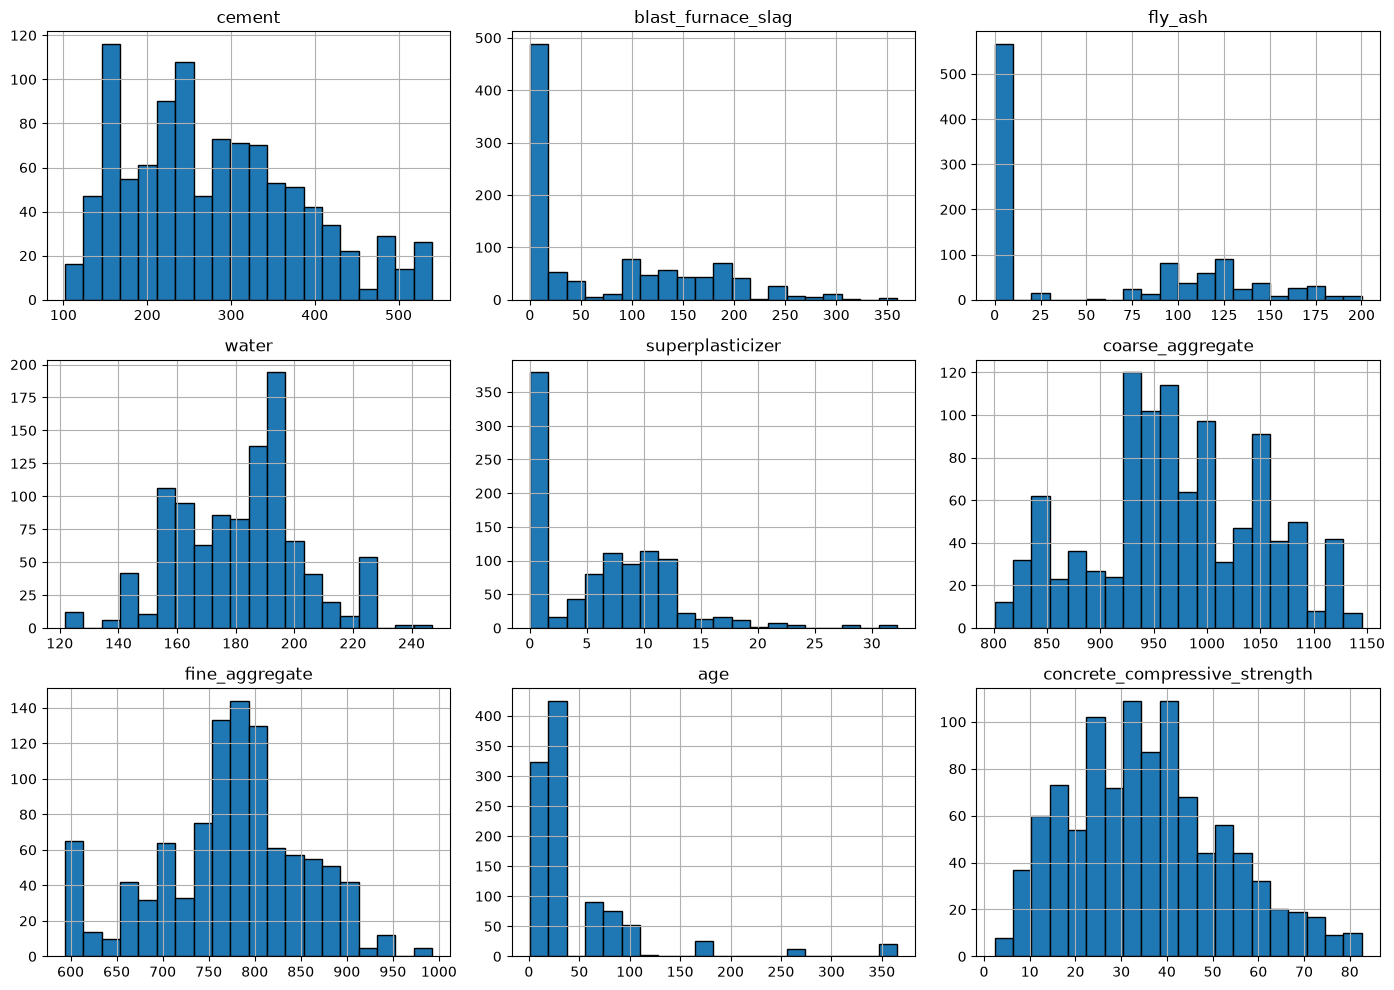

In [8]:
from matplotlib import pyplot as plt

original_cols = [
    "cement",
    "blast_furnace_slag",
    "fly_ash",
    "water",
    "superplasticizer",
    "coarse_aggregate",
    "fine_aggregate",
    "age",
    "concrete_compressive_strength"
]

df[original_cols].hist(
    figsize=(14, 10),
    bins=20,
    edgecolor="black"
)

plt.tight_layout()
plt.show()

In [ ]:
print(f"圧縮強度の分布歪度:",df["concrete_compressive_strength"].skew())

圧縮強度の分布をヒストグラムで確認したところ、データは主に20～45 MPa付近に集中しており、高強度側にやや長い裾を持つ分布が観察された。<br>
記述統計量を確認すると、平均値は35.82 MPa、中央値は34.45 MPaであり、平均値が中央値をわずかに上回っていた。<br>
さらに、歪度（Skewness）を算出した結果、0.417となり、分布が軽度の右偏（正の歪み）を示していることが確認された。<br>
ただし、歪度の絶対値は比較的小さく、著しく非対称な分布ではないと考えられる。

4.2 Log Transformation of Age（養生期間の対数変換）

In [ ]:
df["log_age"] = np.log(df["age"])

plt.figure(figsize=(6,4))
plt.hist(df["log_age"],  
         color = "lightblue", 
         edgecolor='black'
        )
plt.title("Distribution of Age")
plt.xlabel("Days", fontsize=8)
plt.ylabel("Frequency")
plt.show()
plt.clf()

In [ ]:
#### 養生期間の対数変換と分布の比較

養生期間（Age）の分布をヒストグラムで確認したところ、明らかな右偏（正の歪み）が認められた。

そこで、分布の偏りを緩和するため、養生期間に対して自然対数変換（log変換）を行った。

変換後のヒストグラムでは、分布のピークが中央付近に位置し、変換前と比較して左右の非対称性が緩和され、より対称的な分布に近づいていることが視覚的に確認された。

なお、説明変数が正規分布に従うことは、線形回帰分析の必須条件ではない。そのため、本分析における対数変換は、正規性を満たすことを目的としたものではない。

後続の相関分析では、元の養生期間と対数変換後の養生期間について、それぞれ圧縮強度との関係を比較し、回帰モデルへの適用を検討する。

### 5. Correlation Analysis（相関分析）
#### 5.1 Cement vs. Compressive Strength

In [ ]:
from matplotlib import pyplot as plt

fig, ax = plt.subplots(figsize=(6,4))
ax.scatter(df["cement"], 
           df["concrete_compressive_strength"], 
           color="lightblue")
ax.set_xlabel("Cement (kg/m³)")
ax.set_ylabel("Compressive Strength (MPa)")
ax.set_title("Cement Content vs. Compressive Strength")

plt.show()

In [ ]:
from matplotlib import pyplot as plt

fig, ax = plt.subplots(figsize=(6,4))
ax.scatter(df["age"], 
           df["concrete_compressive_strength"], 
           color="lightblue")
ax.set_xlabel("Age")
ax.set_ylabel("Compressive Strength (MPa)")
ax.set_title("Age vs. Compressive Strength")

plt.show()

####  5.2 Age vs. Compressive Strength

In [ ]:
import scipy.stats as stats

r,p = stats.pearsonr(df["cement"], df["concrete_compressive_strength"])
print(r)
print(f"P-value:",p)

セメント量と圧縮強度の間には、中程度の正の相関が認められた（r = 0.498）。

In [ ]:
import scipy.stats as stats

r,p = stats.pearsonr(df["age"], df["concrete_compressive_strength"])
print(r)
print(f"P-value:",p)

 5.2 Log Transformation of Age

In [ ]:
import numpy as np

df["log_age"] = np.log(df["age"])

fig, ax = plt.subplots(figsize=(6,4))
ax.scatter(df["log_age"], 
           df["concrete_compressive_strength"], 
           color="lightblue")
ax.set_xlabel("Log_Age")
ax.set_ylabel("Compressive Strength (MPa)")
ax.set_title("Log_Age vs. Compressive Strength")

plt.show()

In [ ]:
r,p = stats.pearsonr(df["log_age"], df["concrete_compressive_strength"])
print(f"The correalation of log_age and concrete_compressive_strength:",r)
print(f"P-value:",p)

|項目	|Age（原始）|	log(Age)（轉換後）|
|:--|:--|:--|
|Pearson r	|0.3289|	0.5522|
|p-value	|2.11 × 10⁻²⁷	|2.91 × 10⁻⁸³|
|相關方向	|正相關	|正相關|
|線性相關程度	|偏弱至中等	|中等|
|散佈圖	|無明顯直線趨勢	|正向趨勢較清楚|

進一步比較 R²<br>
如果我們分別建立只有一個解釋變數、包含截距的簡單線性回歸模型，則：$ R^2=r^2 $<br>
因此：<br>

|模型|	R²|
|:--|:--|
|Strength ~ Age	|0.108|
|Strength ~ log(Age)	|0.305|

這代表：<br>
原始 Age 的簡單線性模型，能解釋約 10.8% 的抗壓強度樣本變異。<br>
log(Age) 的簡單線性模型，能解釋約 30.5% 的抗壓強度樣本變異。<br>
在這份資料中，對數轉換確實改善了簡單線性模型的擬合程度。<br>
但仍有約 69.5% 的樣本變異未被這個模型解釋。這也提醒我們，材料配方等其他變數可能非常重要。

二、為什麼 log 轉換會改善相關性？

原始模型假設：

$$ Y=\beta_0+\beta_1 Age+\varepsilon $$

代表 Age 每增加一天，抗壓強度的預期變化量固定。

但混凝土強度的發展通常不是這種模式。

例如：

養護時間從 7 天增加到 14 天，與從 180 天增加到 187 天，強度的增加量未必相同。

對數模型則是：

$$ Y=\beta_0+\beta_1\ln(Age)+\varepsilon $$

它允許養護時間增加時，抗壓強度的增加速度逐漸減緩。

假設 \(\beta_1>0\)，模型預測的曲線便會隨 Age 增加而上升，但斜率逐漸下降。

這可能更符合混凝土強度隨養護時間發展的特性。

不過，目前我們還不能說這是最佳模型，因為尚未進行殘差分析，也還沒有控制其他材料配方。

三、你的散佈圖還透露了一個重要問題

仔細觀察，你會發現：

即使轉換成 log_age，在同一個養護天數下，抗壓強度仍然有很大的差異。

例如：

在 log_age ≈ 3.33（Age = 28 天）附近，抗壓強度從約 10 MPa 到 80 MPa 都有。

這表示：

養護天數不是決定抗壓強度的唯一因素。

這也是為什麼接下來我建議使用多元回歸。

我們可以同時考慮：

$$ \begin{aligned} Strength =\;&\beta_0+\beta_1 Cement\\ &+\beta_2 Water\\ &+\beta_3 \ln(Age)+\cdots+\varepsilon \end{aligned} $$

如此一來，就能分析在控制其他材料成分後，養護天數與抗壓強度的關聯。

養生期間（Age）と圧縮強度の関係についてPearsonの相関係数を算出したところ、r = 0.329であり、正の相関が確認された。

散布図から非線形な関係が示唆されたため、養生期間を自然対数変換したうえで再度相関分析を行った。その結果、相関係数はr = 0.552に上昇し、単回帰モデルの決定係数も0.108から0.305に改善した。

以上より、養生期間を対数変換することで、圧縮強度との関係をより適切に記述できる可能性が示された。ただし、材料配合条件などの影響を考慮した追加分析が必要である。

6. Multicollinearity Assessment
   6.1 Correlation Matrix 

In [ ]:
import seaborn as sns

log_df = df.drop(columns=["age","concrete_compressive_strength"])
plt.figure(figsize=(8,6))

corr_grid = log_df.corr()
sns.heatmap(corr_grid,
            xticklabels=corr_grid.columns, 
            yticklabels=corr_grid.columns, 
            vmin=-1, center=0, 
            vmax=1, cmap='PuOr', 
            annot=True, cbar_kws={'shrink': .2})

plt.show()


In [ ]:
print(df.columns.tolist())

In [ ]:

features = [
    "cement",
    "blast_furnace_slag",
    "fly_ash",
    "water",
    "superplasticizer",
    "coarse_aggregate",
    "fine_aggregate",
    "log_age"
]

  6.2 Variance Inflation Factor (VIF)

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

X = df[features]
X_const = sm.add_constant(X)

cement_vif = variance_inflation_factor(
    X_const.values, 1
)

print("Cement VIF:", cement_vif)

In [ ]:
vif_df = pd.DataFrame({
    "Feature": X.columns,
    "VIF": [
        variance_inflation_factor(X_const.values, i)
        for i in range(1, X_const.shape[1])
    ]
})

vif_df

一般常用的參考標準如下：

|VIF	|判斷|
|:--|:--|
|1	|幾乎沒有共線性|
|1～5	|通常沒有嚴重問題|
|5～10	|值得注意|
|>10	|可能有嚴重多重共線性|

|排名	|變數	|VIF	判斷|
|:--|:--|:--|
|1|	cement|	7.53|	⚠️ 偏高|
|2|	blast_furnace_slag|	7.28|	⚠️ 偏高|
|3|	fine_aggregate	|7.03	|⚠️ 偏高|
|4|	water|	6.98|	⚠️ 偏高|
|5|	fly_ash|	6.14	|⚠️ 偏高|
|6|	coarse_aggregate	|5.09	|⚠️ 略高|
|7|	superplasticizer|	2.98|	相對較低|
|8|	log_age	|1.05	|幾乎沒有共線性|

8 個解釋變數中：<br>
6 個變數的 VIF > 5<br>
2 個變數的 VIF < 5<br>
沒有任何變數的 VIF > 10<br>
依照常見經驗標準，部分變數存在值得注意的多重共線性，但還不能直接認定模型無法使用。

為什麼相關係數不高，VIF 卻偏高？<br>
這是這次分析最重要的統計觀念。發現：
cement × fly_ash：r = -0.40<br>
water × superplasticizer：r = -0.66<br>
water × fine_aggregate：r = -0.45<br>
兩兩相關係數都沒有超過 0.7。
但是現在：$ VIF_{\text{cement}}=7.53 $
為什麼？<br>
因為 VIF 不是只檢查兩個變數。它檢查的是：<br>
某個解釋變數能在多大程度上被其他所有解釋變數共同解釋。<br>
例如，cement 的 VIF 為 7.53。<br>
利用公式：$ VIF_j=\frac{1}{1-R_j^2} $<br>
可以反推：$ R_j^2=1-\frac{1}{7.53} $$ $$ R_j^2\approx0.867 $<br>
這代表：其他七個解釋變數共同可以解釋約 86.7% 的 cement 樣本變異。<br>
因此，即使 cement 與某個單一變數的相關性不高，它仍可能與其他多個變數存在較強的線性依賴。<br>
這就是多重共線性。

為什麼混凝土資料容易出現這種情況？

這與資料的物理意義有關。

混凝土由多種材料組成：

水泥
高爐爐渣
飛灰
水
粗骨材
細骨材
減水劑

這些材料的配合比例不是完全獨立的。

例如，如果增加水泥含量，其他材料的使用量可能需要調整。

因此，各種材料之間可能存在結構性的關聯。

這也能解釋為什麼多個材料變數的 VIF 都偏高。

不過，這只是合理的領域解釋；是否存在固定總量限制，仍需要根據資料的收集方式進一步確認。

In [ ]:
y = df["concrete_compressive_strength"]

import statsmodels.api as sm

X_const = sm.add_constant(X)

model = sm.OLS(y, X_const).fit()

print(model.summary())

項目	意義
R-squared	決定係數
Adj. R-squared	調整後決定係數
coef	回歸係數
std err	係數標準誤
t	t 統計量
P>|t|	係數檢定的 p 值
[0.025, 0.975]	95% 信賴區間
F-statistic	整體回歸模型的 F 統計量

In [ ]:
fitted = model.fittedvalues

residuals = model.resid

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))

ax.scatter(fitted, residuals,color="lightblue" )
ax.axhline(y=0, color="red", linestyle="--")
plt.show()

In [ ]:
import statsmodels.api as sm
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4))

sm.qqplot(
    residuals,
    line="s",
    ax=ax
)

ax.set_title("Normal Q-Q Plot of Residuals")

plt.show()

In [ ]:
from statsmodels.stats.diagnostic import het_breuschpagan

bp_test = het_breuschpagan(
    residuals,
    X_const
)
print(bp_test)

In [ ]:
bp_df = pd.DataFrame({
    "Statistic": [
        "LM Statistic",
        "LM p-value",
        "F Statistic",
        "F p-value"
    ],
    "Value": bp_test
})

bp_df

In [ ]:
bp_df["Value"].map(lambda x: f"{x:.4g}")

In [ ]:
from statsmodels.stats.diagnostic import het_breuschpagan

bp_test = het_breuschpagan(
    model.resid,
    X_const
)

bp_df = pd.DataFrame({
    "Statistic": [
        "LM Statistic",
        "LM p-value",
        "F Statistic",
        "F p-value"
    ],
    "Value": bp_test
})

bp_df

In [ ]:
robust_model = model.get_robustcov_results(
    cov_type="HC3"
)
print(robust_model.summary())

In [ ]:
comparison = pd.DataFrame({
    "Feature": model.model.exog_names,
    "Coefficient": model.params.values,
    "OLS_SE": model.bse.values,
    "HC3_SE": robust_model.bse,
    "OLS_p": model.pvalues.values,
    "HC3_p": robust_model.pvalues
})

comparison

In [ ]:
robust_model = model.get_robustcov_results(
    cov_type="HC3"
)

print(robust_model.summary())

In [ ]:
import numpy as np

rmse = np.sqrt(np.mean((y - fitted) ** 2))

print(f"RMSE: {rmse:.3f} MPa")

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(df["concrete_compressive_strength"],fitted)
ax.plot([0, 85], [0, 85], "r--")


ax.set_xlabel("Actual Strength (MPa)")
ax.set_ylabel("Predicted Strength (MPa)")
ax.set_title("Actual vs. Predicted Compressive Strength")

plt.tight_layout()
plt.show()